In [1]:
import sys
sys.path.append("../src")   # notebooks run from notebooks/, so ../src finds our modules

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from data_access import load_sales_enriched

sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.2f}".format

In [2]:
df = load_sales_enriched()

print("Shape:", df.shape)
print("Revenue total:", round(df["revenue_usd"].sum(), 2))
print("Order date range:", df["order_date"].min().date(), "to", df["order_date"].max().date())
print("Missing delivery dates:", df["delivery_date"].isna().sum())
df.dtypes

Shape: (62884, 31)
Revenue total: 55755479.59
Order date range: 2016-01-01 to 2021-02-20
Missing delivery dates: 49719


order_number                  int64
line_item                     int64
order_date            datetime64[s]
delivery_date         datetime64[s]
delivery_days               float64
year                          int64
quarter                       int64
month                         int64
month_name                      str
month_start           datetime64[s]
customer_key                  int64
gender                          str
customer_country                str
customer_continent              str
store_key                     int64
channel                         str
store_country                   str
product_key                   int64
product_name                    str
brand                           str
category                        str
subcategory                     str
quantity                      int64
currency_code                   str
unit_price_usd              float64
unit_cost_usd               float64
revenue_usd                 float64
cost_usd                    

In [3]:
monthly = (
    df.groupby("month_start")
      .agg(revenue=("revenue_usd", "sum"),
           profit=("profit_usd", "sum"),
           orders=("order_number", "nunique"),
           active_days=("order_date", "nunique"))
      .reset_index()
)
monthly = monthly[monthly["month_start"] < "2021-02-01"].copy()   # drop partial Feb 2021
monthly["revenue_12m_avg"] = monthly["revenue"].rolling(12).mean()

print(len(monthly), "months")
print("Last 12-month sum:", round(monthly["revenue"].tail(12).sum(), 0))
monthly.head(3)

61 months
Last 12-month sum: 7738703.0


,month_start,revenue,profit,orders,active_days,revenue_12m_avg
0,2016-01-01,"649,918.78","388,268.96",292,28,NaN
1,2016-02-01,"891,098.30","531,722.75",334,28,NaN
2,2016-03-01,"338,407.36","203,506.99",109,15,NaN


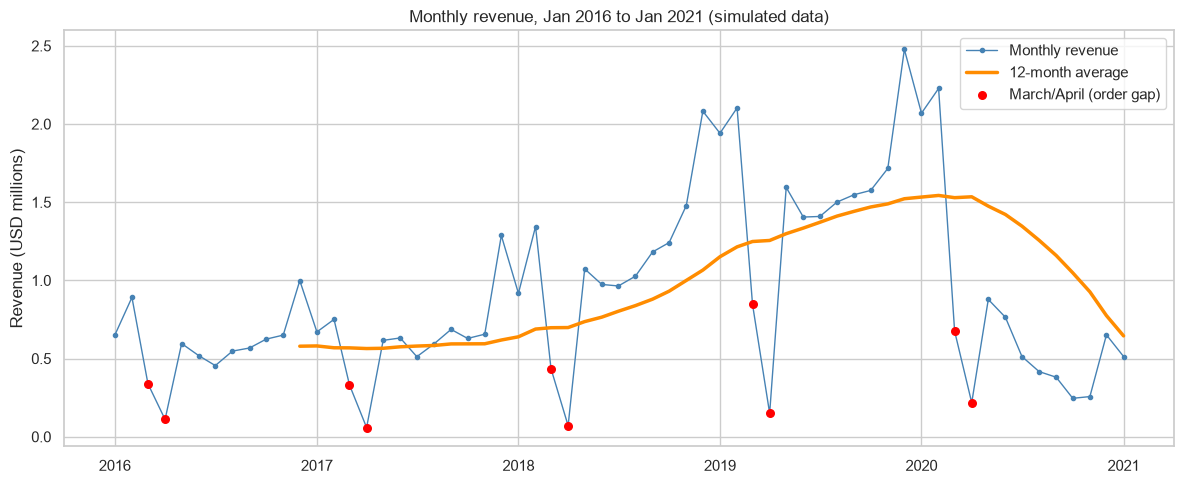

In [4]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(monthly["month_start"], monthly["revenue"] / 1e6,
        marker="o", markersize=3, linewidth=1, color="steelblue", label="Monthly revenue")
ax.plot(monthly["month_start"], monthly["revenue_12m_avg"] / 1e6,
        linewidth=2.5, color="darkorange", label="12-month average")

# Mark March and April, where the annual order gap makes totals unreliable
gap = monthly[monthly["month_start"].dt.month.isin([3, 4])]
ax.scatter(gap["month_start"], gap["revenue"] / 1e6,
           color="red", s=30, zorder=3, label="March/April (order gap)")

ax.set_title("Monthly revenue, Jan 2016 to Jan 2021 (simulated data)")
ax.set_ylabel("Revenue (USD millions)")
ax.set_xlabel("")
ax.legend()
plt.tight_layout()
plt.savefig("../reports/figures/monthly_revenue.png", dpi=150)
plt.show()

           revenue        profit  growth_pct
year                                        
2016  6,946,793.60  4,107,000.50         NaN
2017  7,421,422.30  4,337,064.10        6.80
2018 12,788,960.70  7,464,961.10       72.30
2019 18,264,382.50 10,697,738.90       42.80
2020  9,294,632.10  5,447,460.10      -49.10


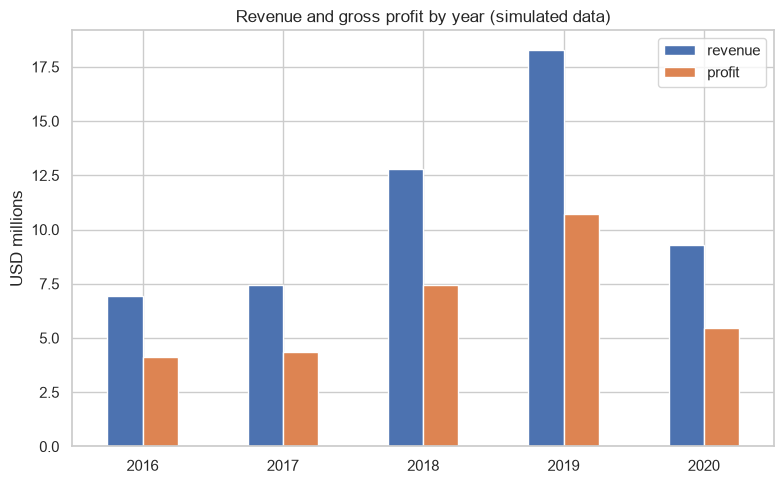

In [5]:
yearly = (
    df[df["year"] <= 2020]               # full years only
      .groupby("year")
      .agg(revenue=("revenue_usd", "sum"), profit=("profit_usd", "sum"))
)
yearly["growth_pct"] = yearly["revenue"].pct_change() * 100
print(yearly.round(1))

ax = (yearly[["revenue", "profit"]] / 1e6).plot(kind="bar", figsize=(8, 5), rot=0)
ax.set_title("Revenue and gross profit by year (simulated data)")
ax.set_ylabel("USD millions")
ax.set_xlabel("")
plt.tight_layout()
plt.savefig("../reports/figures/yearly_revenue_profit.png", dpi=150)
plt.show()


In [10]:
def strip_color(name, color):
    """Remove a trailing colour from a product name (case-insensitive), only if the name really ends with it."""
    if isinstance(color, str) and color and name.lower().endswith(" " + color.lower()):
        return name[: -(len(color) + 1)]
    return name

products["model"] = [strip_color(n, c) for n, c in zip(products["product_name"], products["color"])]

unstripped = products[products["model"] == products["product_name"]]
colour_in_name = unstripped[
    [c.lower() in n.lower() for n, c in zip(unstripped["product_name"], unstripped["color"])]
]
print("Products:", len(products))
print("Distinct models:", products["model"].nunique())
print("Names where no colour was removed:", len(unstripped))
print("...of which the colour appears somewhere in the name (suspicious):", len(colour_in_name))
colour_in_name[["product_key", "product_name", "color"]].head(15)

Products: 2517
Distinct models: 885
Names where no colour was removed: 121
...of which the colour appears somewhere in the name (suspicious): 0


,product_key,product_name,color


In [13]:
# drop() makes this cell safe to re-run (otherwise merge would create model_x / model_y)
df = df.drop(columns="model", errors="ignore").merge(
    products[["product_key", "model"]], on="product_key", how="left"
)
assert len(df) == 62884, "merge changed the row count"
assert df["model"].notna().all(), "some sales rows have no model"

model_rev = (
    df.groupby(["model", "category"])
      .agg(revenue=("revenue_usd", "sum"),
           units=("quantity", "sum"),
           variants_sold=("product_key", "nunique"))
      .reset_index()
      .sort_values("revenue", ascending=False)
)
model_rev["pct_of_revenue"] = 100 * model_rev["revenue"] / model_rev["revenue"].sum()

print("Revenue total:", round(model_rev["revenue"].sum(), 2))
print("Model rows:", len(model_rev), "| distinct model names:", model_rev["model"].nunique())
model_rev.head(15).round(1)

Revenue total: 55755479.59
Model rows: 885 | distinct model names: 885


,model,category,revenue,units,variants_sold,pct_of_revenue
64,Adventure Works Desktop PC2.33 XD233,Computers,"1,814,937.00",1873,4,3.30
846,WWI Desktop PC2.33 X2330,Computers,"1,713,016.00",1864,4,3.10
45,"Adventure Works 52"" LCD HDTV X590",TV and Video,"1,432,595.10",494,4,2.60
307,Contoso Water Heater 7.2GPM X1800,Home Appliances,"1,221,300.00",828,6,2.20
63,Adventure Works Desktop PC2.30 MD230,Computers,"1,150,444.50",1920,4,2.10
845,WWI Desktop PC2.30 M2300,Computers,"977,132.00",1748,4,1.80
306,Contoso Water Heater 4.3GPM M1250,Home Appliances,"956,475.00",1090,7,1.70
62,Adventure Works Desktop PC1.80 ED182,Computers,"853,829.20",1708,4,1.50
389,Fabrikam Refrigerator 24.7CuFt X9800,Home Appliances,"767,997.60",240,7,1.40
305,Contoso Water Heater 4.0GPM M1250,Home Appliances,"703,199.00",889,6,1.30


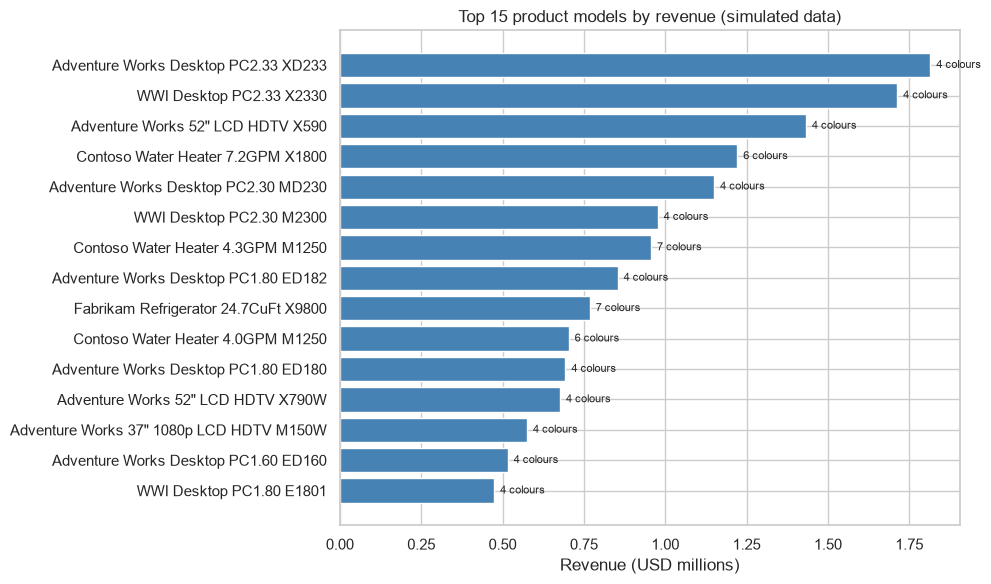

In [14]:
top = model_rev.head(15).iloc[::-1]          # reversed so the biggest bar is on top
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top["model"], top["revenue"] / 1e6, color="steelblue")
for i, (rev, v) in enumerate(zip(top["revenue"], top["variants_sold"])):
    ax.text(rev / 1e6, i, f"  {v} colours", va="center", fontsize=8)
ax.set_title("Top 15 product models by revenue (simulated data)")
ax.set_xlabel("Revenue (USD millions)")
plt.tight_layout()
plt.savefig("../reports/figures/top_models.png", dpi=150)
plt.show()

In [15]:
sorted_pct = model_rev["pct_of_revenue"].cumsum().reset_index(drop=True)
n = len(model_rev)
for target in (25, 50, 80):
    k = int((sorted_pct < target).sum()) + 1
    print(f"{k} models ({100 * k / n:.1f}% of {n}) produce {target}% of revenue")

14 models (1.6% of 885) produce 25% of revenue
64 models (7.2% of 885) produce 50% of revenue
231 models (26.1% of 885) produce 80% of revenue


In [16]:
first_year = df.groupby("customer_key")["order_date"].min().dt.year.rename("first_year")

cust_year = (
    df.groupby(["customer_key", "year"])
      .agg(revenue=("revenue_usd", "sum"), orders=("order_number", "nunique"))
      .reset_index()
      .merge(first_year, on="customer_key")
)
cust_year["status"] = np.where(cust_year["year"] == cust_year["first_year"], "New", "Returning")
assert (cust_year["year"] >= cust_year["first_year"]).all()

print("Customer-year rows:", len(cust_year))
print("Distinct customers:", cust_year["customer_key"].nunique())

Customer-year rows: 21087
Distinct customers: 11887


In [17]:
summary = (
    cust_year.groupby(["year", "status"])
      .agg(active_customers=("customer_key", "nunique"),
           revenue=("revenue", "sum"),
           orders=("orders", "sum"))
      .reset_index()
)
summary["rev_per_customer"] = summary["revenue"] / summary["active_customers"]
summary["orders_per_customer"] = summary["orders"] / summary["active_customers"]
summary = summary[summary["year"] <= 2020]        # 2021 is partial

print(summary.round(1).to_string(index=False))
print()
print("Revenue by year (must match earlier totals):")
print(summary.groupby("year")["revenue"].sum().round(0))
print()
print("New customers by year (must match K1 cohorts):")
print(summary[summary["status"] == "New"].set_index("year")["active_customers"])

 year    status  active_customers       revenue  orders  rev_per_customer  orders_per_customer
 2016       New              2561  6,946,793.60    2865          2,712.50                 1.10
 2017       New              2376  5,990,386.80    2665          2,521.20                 1.10
 2017 Returning               531  1,431,035.50     615          2,695.00                 1.20
 2018       New              3104  8,248,221.20    3833          2,657.30                 1.20
 2018 Returning              1661  4,540,739.50    2132          2,733.70                 1.30
 2019       New              2832  7,537,314.00    3788          2,661.50                 1.30
 2019 Returning              3665 10,727,068.50    5295          2,926.90                 1.40
 2020       New               947  2,104,469.80    1048          2,222.20                 1.10
 2020 Returning              2921  7,190,162.30    3587          2,461.50                 1.20

Revenue by year (must match earlier totals):
year

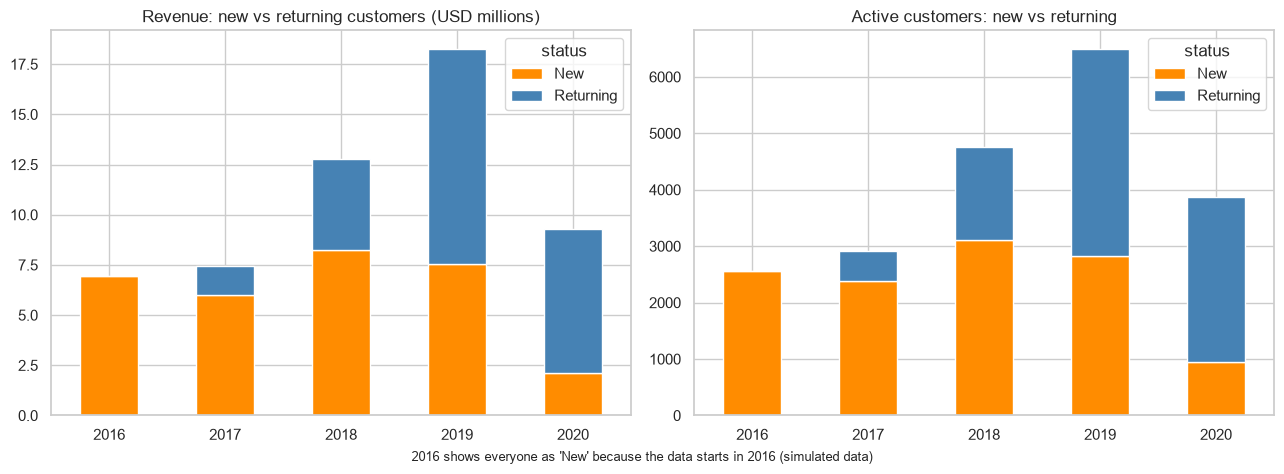

In [18]:
rev = summary.pivot(index="year", columns="status", values="revenue") / 1e6
cust = summary.pivot(index="year", columns="status", values="active_customers")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
rev[["New", "Returning"]].plot(kind="bar", stacked=True, ax=axes[0], rot=0,
                               color=["darkorange", "steelblue"])
axes[0].set_title("Revenue: new vs returning customers (USD millions)")
axes[0].set_xlabel("")
cust[["New", "Returning"]].plot(kind="bar", stacked=True, ax=axes[1], rot=0,
                                color=["darkorange", "steelblue"])
axes[1].set_title("Active customers: new vs returning")
axes[1].set_xlabel("")
plt.suptitle("2016 shows everyone as 'New' because the data starts in 2016 (simulated data)", y=0.02, fontsize=9)
plt.tight_layout()
plt.savefig("../reports/figures/new_vs_returning.png", dpi=150, bbox_inches="tight")
plt.show()

In [19]:
active = cust_year.groupby("year")["customer_key"].apply(set)
rows = []
for y in range(2017, 2021):
    prev, cur = active[y - 1], active[y]
    rows.append({"year": y,
                 "active_prev_year": len(prev),
                 "active_again": len(prev & cur),
                 "retention_pct": round(100 * len(prev & cur) / len(prev), 1)})
print(pd.DataFrame(rows).to_string(index=False))

p = summary.pivot(index="year", columns="status", values="revenue")
chg_new = p.loc[2020, "New"] - p.loc[2019, "New"]
chg_ret = p.loc[2020, "Returning"] - p.loc[2019, "Returning"]
print(f"\nRevenue change 2019 to 2020: new {chg_new:,.0f} | returning {chg_ret:,.0f} | total {chg_new + chg_ret:,.0f}")

 year  active_prev_year  active_again  retention_pct
 2017              2561           531          20.70
 2018              2907          1026          35.30
 2019              4765          2219          46.60
 2020              6497          1853          28.50

Revenue change 2019 to 2020: new -5,432,844 | returning -3,536,906 | total -8,969,750
